# Two plain routes to foreign objects on the lentils belt

A hyperspectral camera finds a stone, a stem or a scrap of paper among lentils because its
spectrum differs from the spectra of lentils and belt. This notebook builds the two plainest
detectors that rest on that fact, from built-in Cuvis.AI nodes only:

1. **Spectral angle to a few reference spectra.** k-means finds three typical spectra of the
   normal product. A pixel whose spectrum points away from all three (a large spectral angle)
   is a candidate.
2. **RX.** One Gaussian background: the mean and the covariance of the 61 bands over normal
   frames. A pixel far from that background (a large Mahalanobis distance) is a candidate.

Both routes end in the same decision: one threshold, calibrated on the validation frames, and
an area filter that keeps only blobs of at least 227 pixels, about a quarter of one lentil.
Each route is fitted on normal frames by the statistical trainer, calibrated on the validation
split and measured on the test split by `AnomalyDetectionMetrics`, all inside the pipeline. The
test pass also writes every test frame, with its hits, false alarms and misses painted in, to one
video per route.

The numbers come from the dataset's own `dinomaly` split and from pixel and frame metrics. They
show how far the two plain routes get on this data; studies that use another split or count
found objects instead of pixels report different numbers.

> **Prerequisites and footprint**
>
> 1. A cuvis-ai environment (`uv sync --extra dev` from the repo root, then `uv run jupyter lab`).
>    The provisioning cell right after the Colab bootstrap installs `cuvis-ai-dataloader[cu3s,coco]`
>    (the cu3s reader, which needs the Cuvis SDK) from the manifests packaged with cuvis-ai.
>    Restart the kernel after a fresh install. Both routes use built-in nodes only, so no model
>    weights are downloaded.
> 2. Disk: the dataset snapshot is ~57 GB and is downloaded in full. Besides that, two split
>    files, the two fitted pipelines (under 40 kB each) and the two test videos (about 43 MB each)
>    land in `outputs/lentils_simple_routes/`.
> 3. Time and memory: on a laptop with an RTX 5070 Ti (12 GB) the notebook runs in about 5 minutes once
>    the dataset is on disk. The kernel peaks at about 10 GB of RAM: the k-means fit holds every
>    pixel of its twelve fit frames (about 3 GB) and a copy of them before it subsamples, so lower
>    `FIT_FRAMES` on a smaller machine. The GPU holds about 5 GB at most; lower
>    `MAX_OPEN_SESSIONS` on a smaller card.
> 4. Google Colab: the bootstrap cell installs cuvis-ai and the Cuvis SDK 3.6.1 from Cubert's public
>    Ubuntu packages (a ~2 GB download).

In [1]:
# Colab bootstrap: a no-op when running locally.
try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # cuvis-ai itself; the next cell provisions the data plugin from the packaged manifests.
    # KMeansClusterer.spectral_signature, which route 1 wires, ships from 0.22.8 on.
    %pip install -q "cuvis-ai>=0.22.8"
    # The C++ Cuvis SDK that reads the cu3s recordings (pip ships only its Python binding):
    # Cubert's public SDK 3.6.1 packages for the image's Ubuntu release (24.04 on Colab today,
    # 22.04 before), a ~2 GB download.
    import platform
    from pathlib import Path

    if not Path("/lib/cuvis").is_dir():  # installed already on the pass after the restart
        ubuntu = platform.freedesktop_os_release()["VERSION_ID"]
        sdk_dir = f"Cuvis 3.6.1/Ubuntu {ubuntu}-amd64-cuda12.9"
        !wget -q -O cuvis_sdk.zip https://cloud.cubert-gmbh.de/s/cuvis_sdk_release_ver_361/download
        !unzip -q -o cuvis_sdk.zip "{sdk_dir}/*.deb" && rm cuvis_sdk.zip
        !apt-get install -y -qq "./{sdk_dir}/cuviscommon_3.6.1-0.deb" "./{sdk_dir}/libcuvis_3.6.1-0.deb" | tail -n 2
    assert Path("/lib/cuvis").is_dir(), "the Cuvis SDK did not install; see the apt-get output"
    %env CUVIS=/lib/cuvis
    # The shared use_cases renderers, pinned to the commit that last touched them.
    !wget -q -O utils.py https://raw.githubusercontent.com/cubert-hyperspectral/cuvis-ai/ceba6e3ef357f9e714d083617b4fa7b13db089d9/notebooks/use_cases/utils.py

    import torch

    if not torch.cuda.is_available():
        print(
            "No GPU detected: the notebook runs on the CPU, slower. Runtime > Change runtime type > GPU."
        )

In [2]:
# Provision the plugins this notebook needs. Their pins live in the plugin manifests packaged with
# cuvis-ai (cuvis_ai/configs/plugins): `provision` reads them off a packaged pipeline that uses the
# same plugins, adds the data module's extras, and installs only what is missing. After a fresh
# install, restart the kernel (Kernel > Restart Kernel) and rerun from the top.
from importlib import invalidate_caches
from importlib.metadata import distributions
from importlib.resources import files

from cuvis_ai_core.utils.provision import resolve_install_specs

CONFIGS = files("cuvis_ai") / "configs"
PLUGINS_DIR = CONFIGS / "plugins"
PROVISION = [  # (packaged pipeline that lists the plugin(s), data module whose extras to add)
    ("anomaly/rx/rx_statistical.yaml", "cu3s_multi"),  # built-in nodes only, plus the cu3s reader
]
before = {(d.name, d.version) for d in distributions()}  # installed packages, for the restart hint
for pipeline_yaml, data_module in PROVISION:
    pipeline_path = CONFIGS / "pipeline" / pipeline_yaml
    if IN_COLAB:  # no uv project on Colab: pip the resolved specs straight into this kernel
        specs = resolve_install_specs(pipeline_path, [PLUGINS_DIR], data_module)
        # pandas<2.4: the plugins ask for pandas>=2.3, and pandas 3 breaks Colab's own cuDF.
        if specs:
            quoted = " ".join(f"'{s}'" for s in specs)
            %pip install -q {quoted} "pandas<2.4"
    else:  # the same command you would run in a terminal from the repo root
        data_arg = f"--data-module {data_module}" if data_module else ""
        !uv run provision --pipeline-path "{pipeline_path}" --plugins-dir "{PLUGINS_DIR}" {data_arg} --apply
# The data module's spec is listed on every run (an importable package does not prove its extras
# are installed), so ask for a restart only when %pip changed the installed packages.
invalidate_caches()  # so importlib.metadata sees what %pip just installed
if IN_COLAB and {(d.name, d.version) for d in distributions()} != before:
    print("Installed; restart the session (Runtime > Restart session) and run again.")

2026-11-10 07:49:53.914 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'cuvis_ai_builtin' tag v0.22.7 \u2192 9bf68f70 from https://github.com/cubert-hyperspectral/cuvis-ai.git
2026-11-10 07:49:54.454 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'cuvis_ai_dataloader' tag v0.9.1 \u2192 809708e6 from https://github.com/cubert-hyperspectral/cuvis-ai-dataloader.git
Using Python 3.13.7 environment at: D:\code-repos\cuvis-ai\wt-6825-simple-routes-nb\.venv
Resolved 69 packages in 1.17s
Audited 69 packages in 4ms


In [3]:
%matplotlib inline
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from loguru import logger

# Robust import whether Jupyter's cwd is the repo root or this notebook folder.
NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / "utils.py").is_file():
    USE_CASES_DIR = NOTEBOOK_DIR
else:
    USE_CASES_DIR = NOTEBOOK_DIR / "notebooks" / "use_cases"
if str(USE_CASES_DIR) not in sys.path:
    sys.path.insert(0, str(USE_CASES_DIR))
REPO_ROOT = USE_CASES_DIR.parent.parent

from utils import display_records_table  # noqa: E402

logger.remove()
logger.add(sys.stderr, level="INFO")

device = (
    "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
)
print(f"device: {device}")

W1110 07:50:11.767000 51240 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


device: cuda


## 1. Knobs

Everything you may want to change sits in one cell. `FIT_FRAMES` sets how many normal frames
the references and the background are fitted on. `N_CLUSTERS` is the number of reference
spectra of route 1. `MIN_AREA` is the smallest blob the area filter keeps; one lentil covers
about 900 pixels at the full 1000 x 1080 frame. `MAX_OPEN_SESSIONS` and `READ_AHEAD` set the
cu3s reader: every recording it keeps open holds about 0.3 to 0.6 GB of GPU memory for the
SDK, and every loader keeps its own set, so the defaults (3 and 1) fit an 8 GB card; on a
24 GB card 6 open recordings read faster. `SDK_ON_GPU = False` processes the cubes on the CPU
instead (no SDK memory on the GPU, slower), the fallback when a run stops with
"Could not process measurement". The SDK picks its device once per process, so restart the
kernel after changing `SDK_ON_GPU` and run from the top.

In [4]:
DATA_DIR = Path("/content/data") if IN_COLAB else REPO_ROOT / "data"  # dataset download root
OUTPUT_DIR = USE_CASES_DIR / "outputs" / "lentils_simple_routes"  # splits and fitted pipelines
FIT_FRAMES = 12  # normal train frames the references and the RX background are fitted on
N_CLUSTERS = 3  # reference spectra of route 1
MIN_AREA = 227  # smallest kept blob in pixels, about a quarter of one lentil
NORMAL_CLASS_IDS = [
    0
]  # COCO id 0 is the unlabeled belt and product; every annotation is a foreign object
MAX_OPEN_SESSIONS = 3  # cu3s recordings kept open per loader; 6 on a 24 GB GPU
READ_AHEAD = 1  # frames read ahead of the model step
SDK_ON_GPU = True  # False: the SDK runs on the CPU (slower); restart the kernel after a change
VIDEO_FPS = 5  # frames per second of the two test videos
# Two test frames shown as stills at the end: a normal frame of 17 March and a frame of
# 3 March with three annotated stems.
PICTURE_FRAMES = [("2026_03_17_11-41-54", 16), ("2026_03_03_13-58-04_2", 32)]

## 2. Data

The dataset ships every frame in `universe.csv` (recording, frame index, COCO file) and its
splits under `splits/`. This notebook uses `splits/dinomaly.json`: its train split holds the
308 frames without any foreign object, from nine recordings, and its validation (148 frames)
and test (180 frames) splits hold normal and annotated frames from all three recording days.

`KMeansClusterer` keeps every pixel of its fit frames in memory before it subsamples them
(about 0.26 GB per frame), so the fit reads `FIT_FRAMES` frames evenly spaced over the 308.
The next cell writes that smaller train split next to the shipped validation and test splits;
RX is fitted on the same frames, which still gives it 13 million pixels for a 61 x 61
covariance.

In [5]:
from cuvis_ai_core.data.public_datasets import PublicDatasets

PublicDatasets.download_dataset("Industrial_FOD_Lentils", download_path=str(DATA_DIR), force=False)
raw_dir = DATA_DIR / "XMR_Industrial_Foreign_Object_Detection_Lentils"
universe_csv = raw_dir / "universe.csv"
splits_doc = json.loads((raw_dir / "splits" / "dinomaly.json").read_text(encoding="utf-8"))

# FIT_FRAMES of the normal train frames, evenly spaced over all of them; val and test as shipped.
train_frames = [(sel, index) for sel in splits_doc["train"] for index in sel["ids"]]
fit_train: dict[str, dict] = {}
for k in np.linspace(0, len(train_frames) - 1, FIT_FRAMES).round().astype(int):
    sel, index = train_frames[k]
    fit_train.setdefault(sel["source"], {**sel, "ids": []})["ids"].append(index)
fit_doc = {**splits_doc, "train": list(fit_train.values())}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fit_splits_json = OUTPUT_DIR / "splits_fit.json"
fit_splits_json.write_text(json.dumps(fit_doc, indent=1), encoding="utf-8")
print({s: sum(len(sel["ids"]) for sel in fit_doc[s]) for s in ("train", "val", "test")})

Industrial_FOD_Lentils: present at D:\code-repos\cuvis-ai\wt-6825-simple-routes-nb\data\XMR_Industrial_Foreign_Object_Detection_Lentils


{'train': 12, 'val': 148, 'test': 180}


In [6]:
from cuvis_ai_dataloader.data import MultiCu3sDataModule
from cuvis_ai_schemas.training.data import DataSplitConfig

# One data module for both routes. Each pass closes its dataset afterwards: every open
# recording holds SDK memory on the GPU, and a later read reopens it.
datamodule = MultiCu3sDataModule(
    universe_csv=str(universe_csv),
    splits=DataSplitConfig(splits_path=str(fit_splits_json)),
    batch_size=1,
    num_workers=0,  # the cuvis SDK reads in this process
    max_open_sessions=MAX_OPEN_SESSIONS,
    read_ahead=READ_AHEAD,
    sdk_cuda=SDK_ON_GPU,
)

## 3. Route 1: spectral angle to three reference spectra

The nodes, in the order the data flows:

- `AnomalyDataNode` turns the cube into float32 and the per-pixel COCO ids into a binary target
  (every id outside `NORMAL_CLASS_IDS` is a foreign object).
- `KMeansClusterer` fits `N_CLUSTERS` centroids on the pixels of the fit frames and sends them
  out on `spectral_signature`, in the layout `SpectralAngleMapper` reads its references from.
- `SpectralAngleMapper` scores every pixel with its smallest angle to the references
  (`best_scores`, in radians). The angle ignores brightness: a darker or brighter lentil keeps
  its angle.
- `BinaryDecider` keeps the pixels whose score lies above its threshold. It compares
  `sigmoid(score)` with the threshold; the calibration below sets it.
- `MaskMinArea` drops the blobs of fewer than `MIN_AREA` pixels (8-connected, labelled per pixel
  with `cell=1`).
- `AnomalyDetectionMetrics` compares the kept pixels with the annotation, per pixel and per frame.

In [7]:
from cuvis_ai.node.clustering import KMeansClusterer
from cuvis_ai.node.data import AnomalyDataNode
from cuvis_ai.node.deciders.binary_decider import BinaryDecider
from cuvis_ai.node.mask_ops import MaskMinArea
from cuvis_ai.node.metrics import AnomalyDetectionMetrics
from cuvis_ai.node.spectral_angle_mapper import SpectralAngleMapper
from cuvis_ai_core.pipeline.pipeline import CuvisPipeline

sam_data = AnomalyDataNode(normal_class_ids=NORMAL_CLASS_IDS, name="data")
kmeans = KMeansClusterer(n_clusters=N_CLUSTERS, max_fit_pixels=60000, random_state=0, name="kmeans")
spectral_angle = SpectralAngleMapper(num_channels=61, name="spectral_angle")
sam_threshold = BinaryDecider(threshold=0.5, name="threshold")
sam_area = MaskMinArea(min_area=MIN_AREA, cell=1, name="area_filter")
sam_metrics = AnomalyDetectionMetrics(name="metrics")
sam_pipeline = CuvisPipeline("lentils_sam_simple")
sam_pipeline.connect(sam_data.outputs.cube, kmeans.inputs.cube)
sam_pipeline.connect(sam_data.outputs.cube, spectral_angle.inputs.cube)
sam_pipeline.connect(kmeans.outputs.spectral_signature, spectral_angle.inputs.spectral_signature)
sam_pipeline.connect(spectral_angle.outputs.best_scores, sam_threshold.inputs.logits)
sam_pipeline.connect(sam_threshold.outputs.decisions, sam_area.inputs.decisions)
sam_pipeline.connect(sam_area.outputs.decisions, sam_metrics.inputs.decisions)
sam_pipeline.connect(sam_data.outputs.mask, sam_metrics.inputs.targets)
sam_pipeline

lentils_sam_simple:
AnomalyDataNode(
  (_binary_mapper): BinaryAnomalyLabelMapper()
)
KMeansClusterer()
SpectralAngleMapper()
BinaryDecider()
MaskMinArea()
AnomalyDetectionMetrics(
  (precision_metric): BinaryPrecision()
  (recall_metric): BinaryRecall()
  (f1_metric): BinaryF1Score()
  (iou_metric): BinaryJaccardIndex()
  (average_precision_metric): BinaryAveragePrecision()
  (image_precision_metric): BinaryPrecision()
  (image_recall_metric): BinaryRecall()
  (image_f1_metric): BinaryF1Score()
)
Use `pipeline.visualize()` for Graphviz/Mermaid output.

The statistical trainer runs the fit frames through the pipeline and fits every node that has a
statistical fit, here `KMeansClusterer`. The fit runs on the CPU, because the k-means fit holds
all pixels of its frames before it draws `max_fit_pixels` of them.

2026-11-10 07:50:14.703 | INFO     | cuvis_ai_core.training.trainers:fit:707 - Training 1 statistical nodes...


2026-11-10 07:50:14.704 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting kmeans


2026-11-10 07:50:27.125 | WARNING  | cuvis_ai_dataloader.data.readers.cu3s_pool:_note_eviction:410 - cu3s reader cache is full (3 open sessions): closing 2026_03_10_11-30-45.cu3s to open 2026_03_03_11-38-39.cu3s. Every such eviction rebuilds a ProcessingContext (about 13 s). Raise max_open_sessions, or set source_coherent_batches=True so a batch stays inside one recording.


2026-11-10 07:50:41.303 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted kmeans


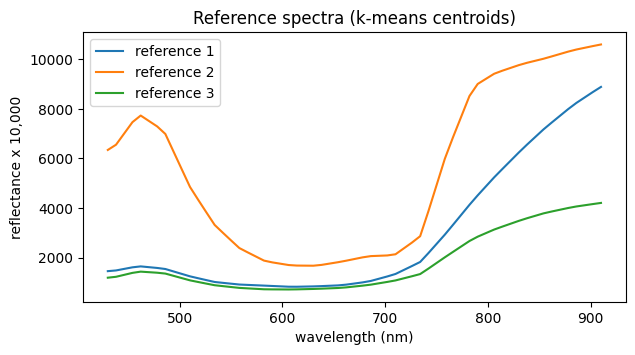

In [8]:
from cuvis_ai_core.training import StatisticalTrainer

sam_pipeline.to("cpu")
sam_trainer = StatisticalTrainer(
    pipeline=sam_pipeline, datamodule=datamodule, metric_nodes=[sam_metrics]
)
sam_trainer.fit()

wavelengths = np.asarray(datamodule.train_ds[0]["wavelengths"], dtype=float).ravel()
datamodule.train_ds.close()
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, reference in enumerate(kmeans.centroids.cpu().numpy()):
    ax.plot(wavelengths, reference, label=f"reference {k + 1}")
ax.set(
    xlabel="wavelength (nm)",
    ylabel="reflectance x 10,000",
    title="Reference spectra (k-means centroids)",
)
ax.legend()
plt.show()

The decider starts at 0.5, which keeps every pixel: the sigmoid of a positive angle lies above
0.5. `calibrate_pipeline_deciders` runs the validation split, collects the scores that feed
each `BinaryDecider` together with the annotation, and moves the threshold to the pixel F1
optimum. It sees the decider's own pixels, before the area filter, so the threshold is the best
one for single pixels; the area filter then removes small blobs on top of it.

In [9]:
from cuvis_ai_core.training.calibration import calibrate_pipeline_deciders

sam_pipeline.to(device)
outcome = calibrate_pipeline_deciders(sam_pipeline, datamodule, split="val")
datamodule.val_ds.close()
print(outcome.summary())
assert outcome.calibrated, "no threshold was calibrated; the decider still holds 0.5"
sam_cut = float(sam_threshold.threshold)
sam_angle = float(np.log(sam_cut / (1.0 - sam_cut)))  # the angle whose sigmoid is the threshold
print(
    f"threshold {sam_cut:.4f} on sigmoid(angle): an angle of {sam_angle:.4f} rad ({np.degrees(sam_angle):.1f} deg)"
)

2026-11-10 07:50:59.710 | WARNING  | cuvis_ai_dataloader.data.readers.cu3s_pool:_note_eviction:410 - cu3s reader cache is full (3 open sessions): closing 2026_03_03_11-31-31.cu3s to open 2026_03_03_13-58-04_2.cu3s. Every such eviction rebuilds a ProcessingContext (about 13 s). Raise max_open_sessions, or set source_coherent_batches=True so a batch stays inside one recording.


2026-11-10 07:51:37.101 | INFO     | cuvis_ai_core.training.calibration:calibrate_pipeline_deciders:581 - Threshold calibration: threshold -> {'class': 'BinaryDecider', 'objective': 'f1', 'level': 'pixels', 'pixel_f1': 0.17306718897863071, 'pixel_precision': 0.11599960664765464, 'pixel_recall': 0.34065902330551306, 'pixel_iou': 0.09473100922735925, 'pixel_tp': 47184, 'pixel_fp': 359576, 'pixel_fn': 91324, 'frame_f1': 0.7241379310344828, 'frame_precision': 0.5675675675675675, 'frame_recall': 1.0, 'frame_iou': 0.5675675675675675, 'frame_tp': 84, 'frame_fp': 64, 'frame_fn': 0, 'frames': 148, 'anomalous_frames': 84, 'threshold': {'old': 0.5, 'new': 0.565849781036377}, 'on_point': {'threshold': 0.565849781036377}, 'f1': 0.17306718897863071, 'precision': 0.11599960664765464, 'recall': 0.34065902330551306}


2026-11-10 07:51:37.102 | INFO     | cuvis_ai_core.training.calibration:calibrate_pipeline_deciders:593 - Threshold calibration: thresholds calibrated on val: threshold (threshold 0.5658)


thresholds calibrated on val: threshold (threshold 0.5658)
threshold 0.5658 on sigmoid(angle): an angle of 0.2649 rad (15.2 deg)


Before the test pass the pipeline gets a second branch that records what the route does on every
test frame. `FixedWavelengthSelector` makes a false-colour image (814 / 622 / 478 nm),
`DecisionOutcomeOverlay` paints the kept pixels onto it against the annotation (yellow: kept and
annotated, red: kept outside any annotation, green: annotated and missed), `ImageConcatenator`
puts the plain and the painted image side by side, and `ToVideoNode` writes the frames to an mp4.
The branch joins after the calibration, so the validation frames stay out of the video, and the
trainer's test pass writes it. `ToVideoNode` prints each frame's position in the pass on the
frame; it reads it from the batch's `frame_id`.

In [10]:
from cuvis_ai.node.anomaly_visualization import DecisionOutcomeOverlay
from cuvis_ai.node.channel_selector import FixedWavelengthSelector
from cuvis_ai.node.compositing import ImageConcatenator
from cuvis_ai.node.video import ToVideoNode

sam_rgb = FixedWavelengthSelector(target_wavelengths=(814.0, 622.0, 478.0), name="false_rgb")
sam_outcome = DecisionOutcomeOverlay(alpha=0.7, name="outcome")
sam_strip = ImageConcatenator(axis="horizontal", gap=8, name="strip")
sam_video = ToVideoNode(
    output_video_path=str(OUTPUT_DIR / "test_spectral_angle.mp4"),
    frame_rate=VIDEO_FPS,
    bitrate="4M",
    name="video",
)

sam_pipeline.connect(sam_data.outputs.cube, sam_rgb.inputs.cube)
sam_pipeline.connect(sam_data.outputs.wavelengths, sam_rgb.inputs.wavelengths)
sam_pipeline.connect(sam_rgb.outputs.rgb_image, sam_outcome.inputs.rgb_image)
sam_pipeline.connect(sam_area.outputs.decisions, sam_outcome.inputs.decisions)
sam_pipeline.connect(sam_data.outputs.mask, sam_outcome.inputs.targets)
sam_pipeline.connect(sam_rgb.outputs.rgb_image, sam_strip.inputs.images)  # left: plain false colour
sam_pipeline.connect(sam_outcome.outputs.rgb_image, sam_strip.inputs.images)  # right: the outcomes
sam_pipeline.connect(sam_strip.outputs.rgb_image, sam_video.inputs.rgb_image)
sam_pipeline.to(device)  # the new nodes join the others on the device
sam_pipeline

lentils_sam_simple:
AnomalyDataNode(
  (_binary_mapper): BinaryAnomalyLabelMapper()
)
KMeansClusterer()
SpectralAngleMapper()
BinaryDecider()
MaskMinArea()
AnomalyDetectionMetrics(
  (precision_metric): BinaryPrecision()
  (recall_metric): BinaryRecall()
  (f1_metric): BinaryF1Score()
  (iou_metric): BinaryJaccardIndex()
  (average_precision_metric): BinaryAveragePrecision()
  (image_precision_metric): BinaryPrecision()
  (image_recall_metric): BinaryRecall()
  (image_f1_metric): BinaryF1Score()
)
FixedWavelengthSelector()
DecisionOutcomeOverlay()
ImageConcatenator()
ToVideoNode()
Use `pipeline.visualize()` for Graphviz/Mermaid output.

The test pass runs the test split once at the test stage; `AnomalyDetectionMetrics` pools its
counts over all 180 frames and the trainer reads them off the node. `close()` finishes the mp4.

In [11]:
sam_test = sam_trainer.test()
datamodule.test_ds.close()
sam_video.close()
sam_test.metrics

2026-11-10 07:51:53.662 | WARNING  | cuvis_ai_dataloader.data.readers.cu3s_pool:_note_eviction:410 - cu3s reader cache is full (3 open sessions): closing 2026_03_03_11-31-31.cu3s to open 2026_03_03_13-58-04_2.cu3s. Every such eviction rebuilds a ProcessingContext (about 13 s). Raise max_open_sessions, or set source_coherent_batches=True so a batch stays inside one recording.


{'metrics/precision': 0.18681243062019348,
 'metrics/recall': 0.2665848135948181,
 'metrics/f1_score': 0.21968090534210205,
 'metrics/iou': 0.12339411675930023,
 'metrics/image_precision': 0.7333333492279053,
 'metrics/image_recall': 0.8839285969734192,
 'metrics/image_f1': 0.8016194105148315}

## 4. Route 2: RX against one Gaussian background

`RXGlobal` streams the mean and the covariance of the 61 bands over the fit pixels and scores
every pixel with its squared Mahalanobis distance to that background. The distances run into
the hundreds and thousands, far past the range where a sigmoid can still tell two scores
apart, so `ScoreToLogit` maps them to `scale * (score - bias)` before the decider. Its fit sets
the bias to the mean plus two standard deviations of the fit scores; the scale stays at 0.01,
which keeps the sigmoid below 1.0 up to scores of about 1,700. The rest of the route, the video
branch included, is the same as route 1.

In [12]:
from cuvis_ai.node.anomaly.rx_detector import RXGlobal
from cuvis_ai.node.conversion import ScoreToLogit

rx_data = AnomalyDataNode(normal_class_ids=NORMAL_CLASS_IDS, name="data")
rx = RXGlobal(num_channels=61, eps=1e-6, name="rx")
rx_logit = ScoreToLogit(init_scale=0.01, name="to_logit")
rx_threshold = BinaryDecider(threshold=0.5, name="threshold")
rx_area = MaskMinArea(min_area=MIN_AREA, cell=1, name="area_filter")
rx_metrics = AnomalyDetectionMetrics(name="metrics")
rx_pipeline = CuvisPipeline("lentils_rx_simple")
rx_pipeline.connect(rx_data.outputs.cube, rx.inputs.data)
rx_pipeline.connect(rx.outputs.scores, rx_logit.inputs.scores)
rx_pipeline.connect(rx_logit.outputs.logits, rx_threshold.inputs.logits)
rx_pipeline.connect(rx_threshold.outputs.decisions, rx_area.inputs.decisions)
rx_pipeline.connect(rx_area.outputs.decisions, rx_metrics.inputs.decisions)
rx_pipeline.connect(rx_data.outputs.mask, rx_metrics.inputs.targets)
rx_pipeline

lentils_rx_simple:
AnomalyDataNode(
  (_binary_mapper): BinaryAnomalyLabelMapper()
)
RXGlobal(
  (_welford): WelfordAccumulator()
)
ScoreToLogit(
  (_welford): WelfordAccumulator()
)
BinaryDecider()
MaskMinArea()
AnomalyDetectionMetrics(
  (precision_metric): BinaryPrecision()
  (recall_metric): BinaryRecall()
  (f1_metric): BinaryF1Score()
  (iou_metric): BinaryJaccardIndex()
  (average_precision_metric): BinaryAveragePrecision()
  (image_precision_metric): BinaryPrecision()
  (image_recall_metric): BinaryRecall()
  (image_f1_metric): BinaryF1Score()
)
Use `pipeline.visualize()` for Graphviz/Mermaid output.

In [13]:
rx_pipeline.to("cpu")
rx_trainer = StatisticalTrainer(
    pipeline=rx_pipeline, datamodule=datamodule, metric_nodes=[rx_metrics]
)
rx_trainer.fit()
datamodule.train_ds.close()
print(
    f"background fitted on {FIT_FRAMES} frames; logit bias {float(rx_logit.bias):.1f}, scale {float(rx_logit.scale):g}"
)

2026-11-10 07:52:34.000 | INFO     | cuvis_ai_core.training.trainers:fit:707 - Training 2 statistical nodes...


2026-11-10 07:52:34.001 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting rx


2026-11-10 07:52:45.849 | WARNING  | cuvis_ai_dataloader.data.readers.cu3s_pool:_note_eviction:410 - cu3s reader cache is full (3 open sessions): closing 2026_03_03_11-11-01.cu3s to open 2026_03_17_11-41-54.cu3s. Every such eviction rebuilds a ProcessingContext (about 13 s). Raise max_open_sessions, or set source_coherent_batches=True so a batch stays inside one recording.


2026-11-10 07:52:53.598 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted rx


2026-11-10 07:52:53.599 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting to_logit


2026-11-10 07:53:02.643 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted to_logit


background fitted on 12 frames; logit bias 51.3, scale 0.01


In [14]:
rx_pipeline.to(device)
outcome = calibrate_pipeline_deciders(rx_pipeline, datamodule, split="val")
datamodule.val_ds.close()
print(outcome.summary())
assert outcome.calibrated, "no threshold was calibrated; the decider still holds 0.5"
rx_cut = float(rx_threshold.threshold)
rx_score = float(rx_logit.bias) + float(np.log(rx_cut / (1.0 - rx_cut))) / float(rx_logit.scale)
print(f"threshold {rx_cut:.4f} on sigmoid(logit): an RX score of {rx_score:.1f}")

2026-11-10 07:53:17.996 | WARNING  | cuvis_ai_dataloader.data.readers.cu3s_pool:_note_eviction:410 - cu3s reader cache is full (3 open sessions): closing 2026_03_03_11-31-31.cu3s to open 2026_03_03_13-58-04_2.cu3s. Every such eviction rebuilds a ProcessingContext (about 13 s). Raise max_open_sessions, or set source_coherent_batches=True so a batch stays inside one recording.


2026-11-10 07:53:53.434 | INFO     | cuvis_ai_core.training.calibration:calibrate_pipeline_deciders:581 - Threshold calibration: threshold -> {'class': 'BinaryDecider', 'objective': 'f1', 'level': 'pixels', 'pixel_f1': 0.13286857069425256, 'pixel_precision': 0.11969646102730924, 'pixel_recall': 0.14929823548098306, 'pixel_iou': 0.07116187356112198, 'pixel_tp': 20679, 'pixel_fp': 152083, 'pixel_fn': 117829, 'frame_f1': 0.7304347826086955, 'frame_precision': 0.5753424657534246, 'frame_recall': 1.0, 'frame_iou': 0.5753424657534246, 'frame_tp': 84, 'frame_fp': 62, 'frame_fn': 0, 'frames': 148, 'anomalous_frames': 84, 'threshold': {'old': 0.5, 'new': 0.9190448522567749}, 'on_point': {'threshold': 0.9190451502799988}, 'f1': 0.13286857069425256, 'precision': 0.11969646102730924, 'recall': 0.14929823548098306}


2026-11-10 07:53:53.435 | INFO     | cuvis_ai_core.training.calibration:calibrate_pipeline_deciders:593 - Threshold calibration: thresholds calibrated on val: threshold (threshold 0.919)


thresholds calibrated on val: threshold (threshold 0.919)
threshold 0.9190 on sigmoid(logit): an RX score of 294.3


In [15]:
rx_rgb = FixedWavelengthSelector(target_wavelengths=(814.0, 622.0, 478.0), name="false_rgb")
rx_outcome = DecisionOutcomeOverlay(alpha=0.7, name="outcome")
rx_strip = ImageConcatenator(axis="horizontal", gap=8, name="strip")
rx_video = ToVideoNode(
    output_video_path=str(OUTPUT_DIR / "test_rx.mp4"),
    frame_rate=VIDEO_FPS,
    bitrate="4M",
    name="video",
)

rx_pipeline.connect(rx_data.outputs.cube, rx_rgb.inputs.cube)
rx_pipeline.connect(rx_data.outputs.wavelengths, rx_rgb.inputs.wavelengths)
rx_pipeline.connect(rx_rgb.outputs.rgb_image, rx_outcome.inputs.rgb_image)
rx_pipeline.connect(rx_area.outputs.decisions, rx_outcome.inputs.decisions)
rx_pipeline.connect(rx_data.outputs.mask, rx_outcome.inputs.targets)
rx_pipeline.connect(rx_rgb.outputs.rgb_image, rx_strip.inputs.images)
rx_pipeline.connect(rx_outcome.outputs.rgb_image, rx_strip.inputs.images)
rx_pipeline.connect(rx_strip.outputs.rgb_image, rx_video.inputs.rgb_image)
rx_pipeline.to(device)

lentils_rx_simple:
AnomalyDataNode(
  (_binary_mapper): BinaryAnomalyLabelMapper()
)
RXGlobal(
  (_welford): WelfordAccumulator()
)
ScoreToLogit(
  (_welford): WelfordAccumulator()
)
BinaryDecider()
MaskMinArea()
AnomalyDetectionMetrics(
  (precision_metric): BinaryPrecision()
  (recall_metric): BinaryRecall()
  (f1_metric): BinaryF1Score()
  (iou_metric): BinaryJaccardIndex()
  (average_precision_metric): BinaryAveragePrecision()
  (image_precision_metric): BinaryPrecision()
  (image_recall_metric): BinaryRecall()
  (image_f1_metric): BinaryF1Score()
)
FixedWavelengthSelector()
DecisionOutcomeOverlay()
ImageConcatenator()
ToVideoNode()
Use `pipeline.visualize()` for Graphviz/Mermaid output.

In [16]:
rx_test = rx_trainer.test()
datamodule.test_ds.close()
rx_video.close()
rx_test.metrics

2026-11-10 07:54:09.358 | WARNING  | cuvis_ai_dataloader.data.readers.cu3s_pool:_note_eviction:410 - cu3s reader cache is full (3 open sessions): closing 2026_03_03_11-31-31.cu3s to open 2026_03_03_13-58-04_2.cu3s. Every such eviction rebuilds a ProcessingContext (about 13 s). Raise max_open_sessions, or set source_coherent_batches=True so a batch stays inside one recording.


{'metrics/precision': 0.22505375742912292,
 'metrics/recall': 0.14847484230995178,
 'metrics/f1_score': 0.1789143979549408,
 'metrics/iou': 0.0982460081577301,
 'metrics/image_precision': 0.7954545617103577,
 'metrics/image_recall': 0.625,
 'metrics/image_f1': 0.699999988079071}

## 5. Both routes on the test split

The `image_*` numbers count frames: a frame counts as flagged when any pixel survives the area
filter, and as anomalous when it carries an annotation. The other numbers count pixels against
the annotated object masks.

In [17]:
NAMES = ("image_precision", "image_recall", "image_f1", "precision", "recall", "f1_score", "iou")
rows = []
for route, summary, threshold in (
    ("spectral angle", sam_test, f"{sam_angle:.3f} rad"),
    ("RX", rx_test, f"{rx_score:.0f}"),
):
    rows.append(
        {
            "route": route,
            "threshold": threshold,
            **{n: summary.metrics[f"metrics/{n}"] for n in NAMES},
        }
    )
display_records_table(
    rows, ("route", "threshold", *NAMES), title=f"Test split, {sam_test.frames} frames"
)

**Test split, 180 frames**

| route | threshold | image_precision | image_recall | image_f1 | precision | recall | f1_score | iou |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| spectral angle | 0.265 rad | 0.7333 | 0.8839 | 0.8016 | 0.1868 | 0.2666 | 0.2197 | 0.1234 |
| RX | 294 | 0.7955 | 0.6250 | 0.7000 | 0.2251 | 0.1485 | 0.1789 | 0.0982 |

## 6. The test split on video

Each route wrote its 180 test frames to `outputs/lentils_simple_routes/test_<route>.mp4`: the
plain false-colour image on the left, the outcomes on the right (yellow: kept and annotated, red:
kept outside any annotation, green: annotated and missed), the frame's position in the pass at the
top left. The next cell plays both videos in Jupyter and shows the two picture frames as stills
read back from them; the test pass ran the frames in the order of the test selectors, so a frame's
position follows from the split file.

test_spectral_angle.mp4: 43.3 MB


test_rx.mp4: 43.4 MB


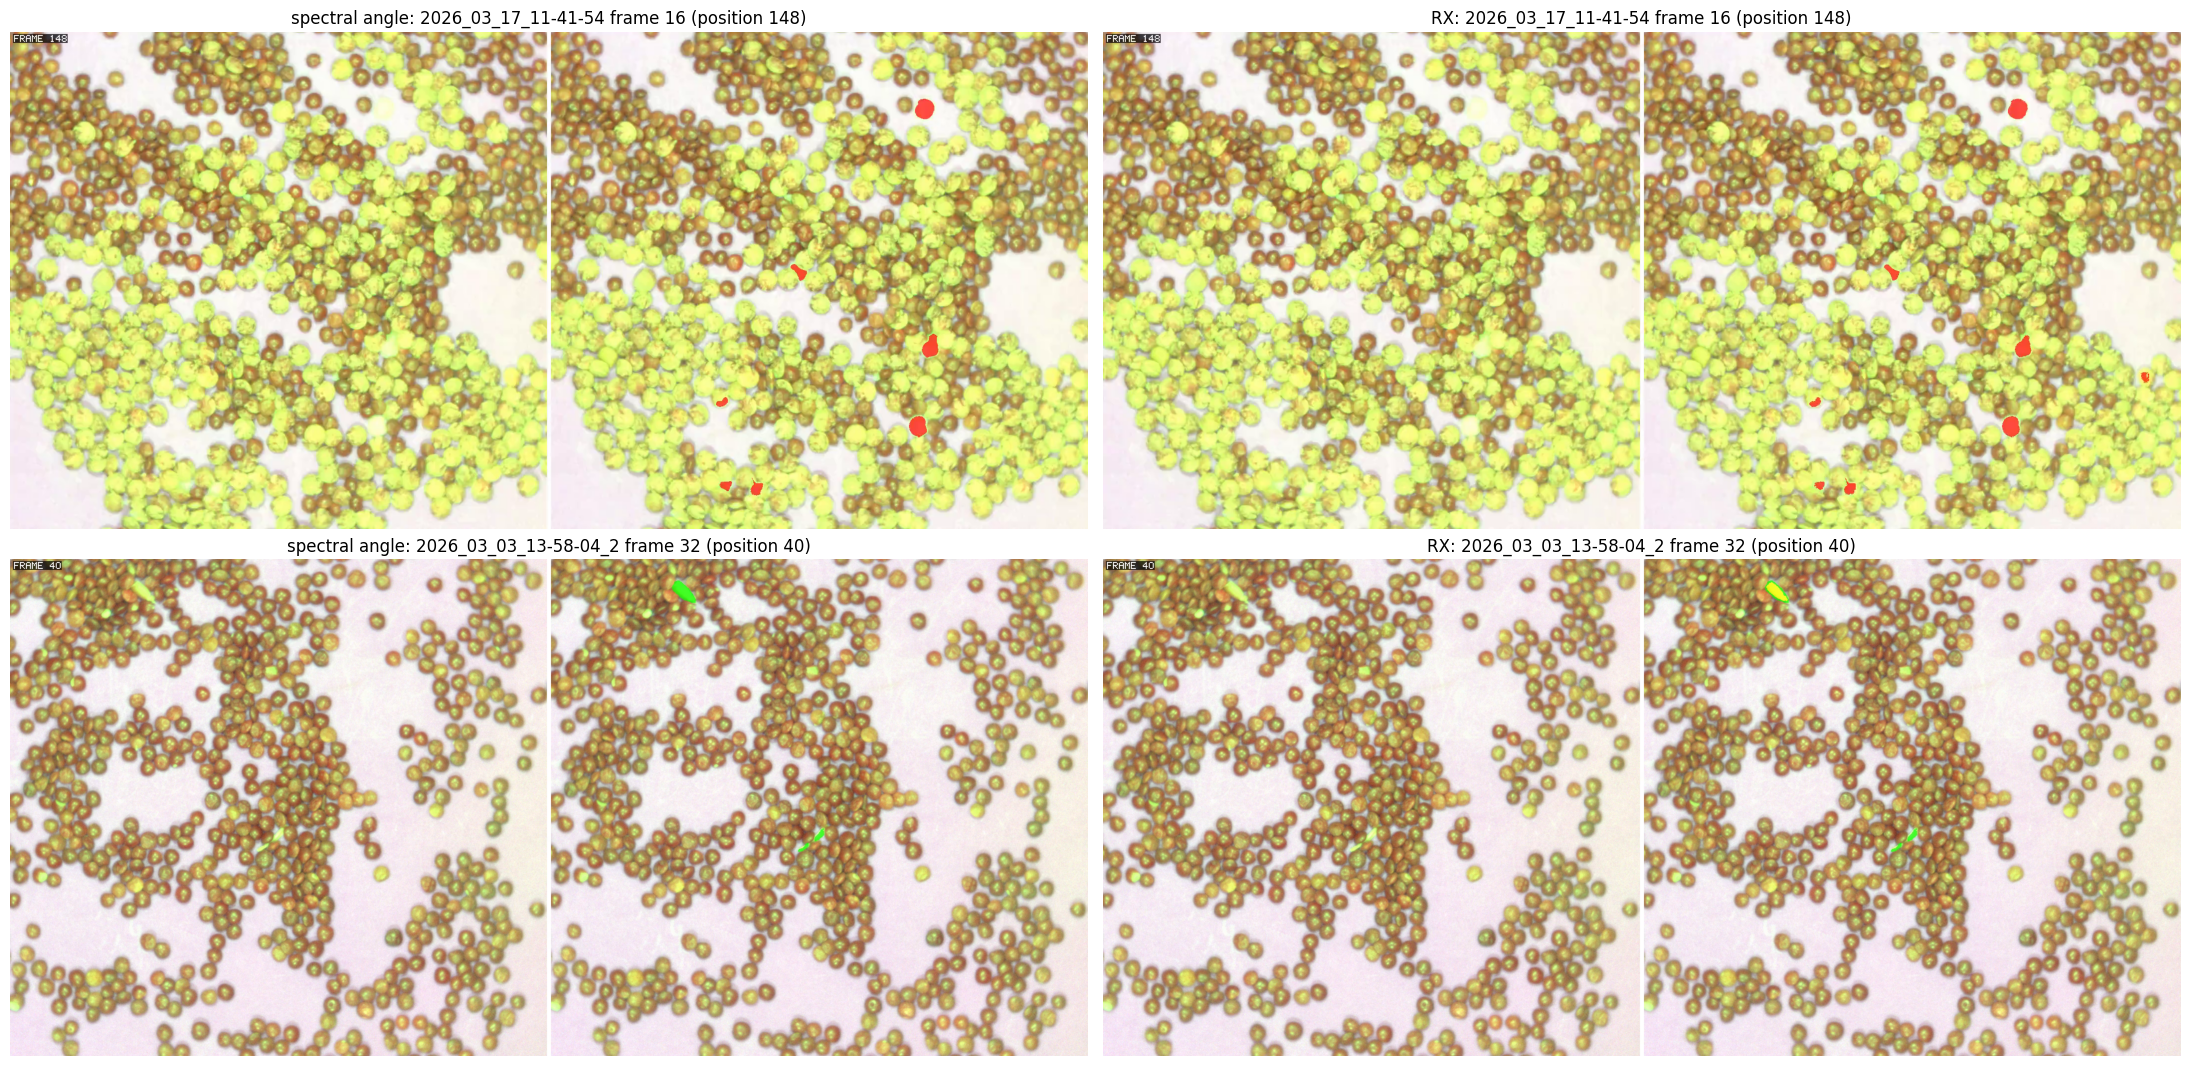

In [18]:
import os

import cv2
from IPython.display import Video, display

test_order = [
    (Path(sel["source"]).stem, index) for sel in splits_doc["test"] for index in sel["ids"]
]
for video in (sam_video, rx_video):
    path = video.output_video_path
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")
    display(Video(Path(os.path.relpath(path)).as_posix(), width=960))  # a path below Jupyter's root

fig, axes = plt.subplots(len(PICTURE_FRAMES), 2, figsize=(22, 5.4 * len(PICTURE_FRAMES)))
for row, (stem, index) in enumerate(PICTURE_FRAMES):
    position = test_order.index((stem, index))
    for col, (route, video) in enumerate((("spectral angle", sam_video), ("RX", rx_video))):
        capture = cv2.VideoCapture(str(video.output_video_path))
        capture.set(cv2.CAP_PROP_POS_FRAMES, position)
        ok, frame = capture.read()
        capture.release()
        assert ok, f"no frame {position} in {video.output_video_path}"
        axes[row, col].imshow(frame[..., ::-1])  # OpenCV reads BGR
        axes[row, col].set_title(f"{route}: {stem} frame {index} (position {position})")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 7. Save the fitted pipelines

Each pipeline goes to a YAML file with the graph, the calibrated thresholds and the video branch,
and a `.pt` file with the fitted references, background and logit bias. The cell also fills in
the YAML's `plugins:` list, which a pipeline built in Python leaves empty, and writes a split file
whose predict stage holds the two picture frames. `restore-pipeline` runs a saved pair on
recordings from a terminal; the cell prints the command that runs the RX pair on the two picture
frames from the repo root, with the dataset in `data/` as in a local run of this notebook. Its
`--override` sends the video to a file of its own, so the test video stays as it is.

In [19]:
import yaml

picture_doc = {**splits_doc, "train": [], "val": [], "test": [], "predict": []}
for stem, index in PICTURE_FRAMES:
    sel = next(s for s in splits_doc["test"] if Path(s["source"]).stem == stem)
    picture_doc["predict"].append({**sel, "ids": [index]})
picture_splits_json = OUTPUT_DIR / "splits_pictures.json"
picture_splits_json.write_text(json.dumps(picture_doc, indent=1), encoding="utf-8")

for pipeline in (sam_pipeline, rx_pipeline):
    yaml_path = OUTPUT_DIR / f"{pipeline.name}.yaml"
    pipeline.save_to_file(yaml_path)
    # A pipeline built in Python is saved with `plugins: null`, and restore-pipeline needs the
    # plugin list. Every node here ships with cuvis-ai, so the list is its built-in plugin.
    config = yaml.safe_load(yaml_path.read_text(encoding="utf-8"))
    config["plugins"] = ["cuvis_ai_builtin"]
    yaml_path.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
    print(sorted(p.name for p in OUTPUT_DIR.glob(f"{pipeline.name}.*")))

video_index = next(i for i, node in enumerate(config["nodes"]) if node["name"] == "video")


def rel(path: Path) -> str:
    """The path relative to the repo root, as the terminal command takes it."""
    return Path(os.path.relpath(path, REPO_ROOT)).as_posix()


print(
    "uv run restore-pipeline"
    f" --pipeline-path {rel(OUTPUT_DIR / 'lentils_rx_simple.yaml')}"
    " --plugins-dir cuvis_ai/configs/plugins --data-module cu3s_multi"
    f" --data-arg universe_csv={rel(universe_csv)}"
    f" --splits {rel(picture_splits_json)}"
    f" --override nodes.{video_index}.hparams.output_video_path={rel(OUTPUT_DIR / 'restored_rx.mp4')}"
)

2026-11-10 07:54:51.981 | INFO     | cuvis_ai_core.pipeline.pipeline:save_to_file:640 - Pipeline saved: Config=D:\code-repos\cuvis-ai\wt-6825-simple-routes-nb\notebooks\use_cases\outputs\lentils_simple_routes\lentils_sam_simple.yaml, Weights=D:\code-repos\cuvis-ai\wt-6825-simple-routes-nb\notebooks\use_cases\outputs\lentils_simple_routes\lentils_sam_simple.pt


2026-11-10 07:54:51.995 | INFO     | cuvis_ai_core.pipeline.pipeline:save_to_file:640 - Pipeline saved: Config=D:\code-repos\cuvis-ai\wt-6825-simple-routes-nb\notebooks\use_cases\outputs\lentils_simple_routes\lentils_rx_simple.yaml, Weights=D:\code-repos\cuvis-ai\wt-6825-simple-routes-nb\notebooks\use_cases\outputs\lentils_simple_routes\lentils_rx_simple.pt


['lentils_sam_simple.pt', 'lentils_sam_simple.yaml']
['lentils_rx_simple.pt', 'lentils_rx_simple.yaml']
uv run restore-pipeline --pipeline-path notebooks/use_cases/outputs/lentils_simple_routes/lentils_rx_simple.yaml --plugins-dir cuvis_ai/configs/plugins --data-module cu3s_multi --data-arg universe_csv=data/XMR_Industrial_Foreign_Object_Detection_Lentils/universe.csv --splits notebooks/use_cases/outputs/lentils_simple_routes/splits_pictures.json --override nodes.9.hparams.output_video_path=notebooks/use_cases/outputs/lentils_simple_routes/restored_rx.mp4


## 8. What the numbers say

All numbers are for the 180 test frames of `splits/dinomaly.json`, with lentil stems counted as
foreign objects.

Both routes find most frames that hold an object: the spectral angle route flags 88 % of them and
RX 62.5 %. RX raises fewer alarms on normal frames (frame precision 0.80 against 0.73), but its
lower recall leaves it with the lower frame F1, 0.70 against 0.80.

Neither route outlines the objects well. Pixel F1 is 0.22 for the spectral angle and 0.18 for RX,
IoU 0.123 and 0.098: most kept pixels lie outside an annotation, and most annotated pixels are
missed.

The videos show both effects frame by frame, and the two stills pick out one of each. On the
normal frame of 17 March each route keeps a few blobs outside any annotation (red). Frame 32 of
3 March holds three annotated stems: RX keeps the largest one (yellow), and both routes lose the
two small ones (green). The spectral angle keeps nothing on that frame at its threshold of
15.2 degrees.

RX also works with fewer directions than its 61 bands offer. `RXGlobal` stores the covariance
in float32 and inverts it with the default pseudo-inverse cutoff, which on this fit keeps 20 of
the 61 directions; the distance ignores the other 41, the directions in which the normal frames
vary least.

The spectral angle numbers also move a little from run to run. scikit-learn's k-means runs on
several threads and does not repeat bit for bit, so the reference spectra differ in their last
digits, and blobs close to the threshold or to the 227 pixel limit can flip. Over four runs of
this notebook its frame recall was 0.88 to 0.90; RX gave the same numbers every time.

Much of this comes from the threshold. The calibration picks the value with the best pixel F1 on
the 148 validation frames, before the area filter drops blobs under 227 pixels, and one value
serves every recording. A threshold set for a chosen false-alarm rate on normal frames, one
threshold per recording day, or more reference spectra (`N_CLUSTERS`) would each move these
numbers.

A sweep of `N_CLUSTERS` under this notebook's split and calibration, with k-means on one thread so
every fit repeats, gave a frame recall of 0.95 to 0.97 for 8 to 20 reference spectra against 0.90
for three, a pixel F1 of 0.24 to 0.26, and the same frame precision of 0.72 to 0.75 at every
size; above 20 the recall fell to 0.74 to 0.79. Those are test-split numbers, so they show the
trend and do not pick a value.